<a href="https://colab.research.google.com/github/kaluarachchiteshan/agromaster-risk-calculation-ml/blob/09_interpretation/notebooks/09_interpretation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# 09 - Interpretation of the final XGBoost model (proposal 4.9) | Group 41 AgroMaster
# Feature importance, SHAP values and an analysis of the most costly mistakes (High risk predicted as Low).
from google.colab import drive
drive.mount('/content/drive')

import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb

OUT_DIR = "/content/drive/MyDrive/agromaster"
FIG_DIR = os.path.join(OUT_DIR, "figures"); os.makedirs(FIG_DIR, exist_ok=True)
SEED = 42
SHAP_ROWS = 20_000         # random test rows used for SHAP (enough for stable averages, fast to compute)

cfg = json.load(open(os.path.join(OUT_DIR, "feature_config.json")))
EXTRA = json.load(open(os.path.join(OUT_DIR, "extended_features.json")))["extra_features"]
FEATS = cfg["num_features"] + EXTRA + cfg["cat_features"]          # same column order as the model input
CLASS_NAMES = ["Low", "Medium", "High"]

pred = pd.read_parquet(os.path.join(OUT_DIR, "test_predictions.parquet")).reset_index(drop=True)
X = pd.DataFrame(np.load(os.path.join(OUT_DIR, "final_X_test_tree.npy")), columns=FEATS)   # rows in the same order as pred
model = xgb.XGBClassifier(); model.load_model(os.path.join(OUT_DIR, "final_xgboost.json"))
assert len(pred) == len(X)
print(f"{len(pred):,} test rows | {len(FEATS)} features")

Mounted at /content/drive
613,070 test rows | 25 features


XGBoost feature importance (share of total gain):
rel_mean_90       0.5918
commodity         0.0497
change_1          0.0457
cv_30             0.0455
season            0.0356
rel_ma_7          0.0285
volatility_30     0.0284
change_30         0.0224
trend_30_90       0.0211
month             0.0211
day_of_year       0.0167
state             0.0144
modal_lag_30      0.0095
rel_ma_30         0.0095
year              0.0093
ma_30             0.0077
modal_price       0.0075
price_spread      0.0064
price_momentum    0.0063
min_price         0.0050
spread_ratio      0.0044
max_price         0.0042
ma_7              0.0033
modal_lag_7       0.0031
modal_lag_1       0.0029

Mean |SHAP| per class (how strongly each feature moves the prediction):
                   Low  Medium    High
rel_mean_90     1.3491  0.5834  1.2952
commodity       0.3238  0.0668  0.2504
year            0.1465  0.0236  0.2314
cv_30           0.0267  0.0826  0.1769
state           0.1207  0.0269  0.1728
ma_30           0.

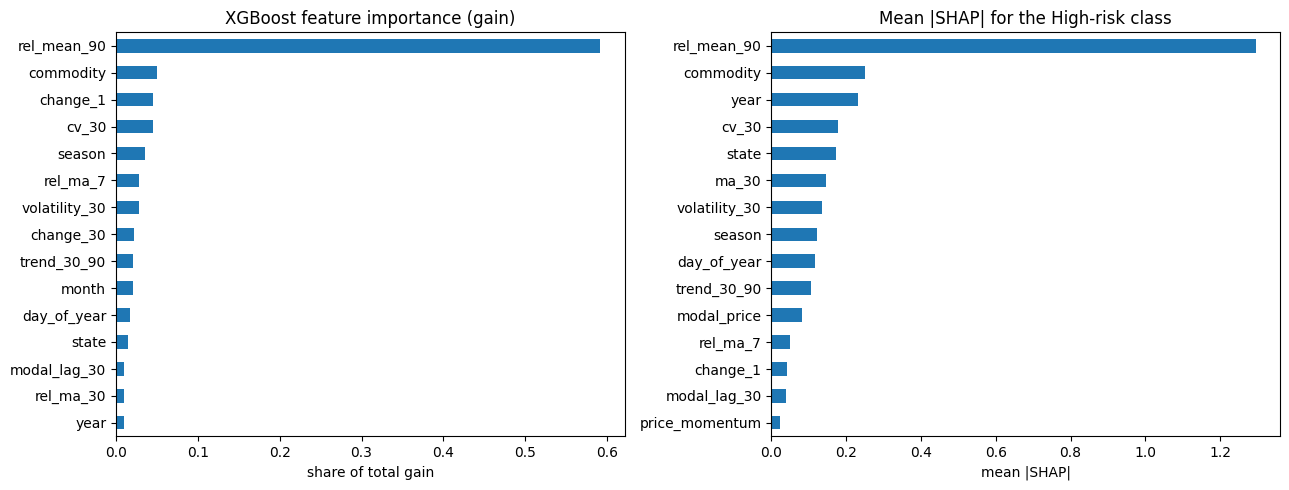

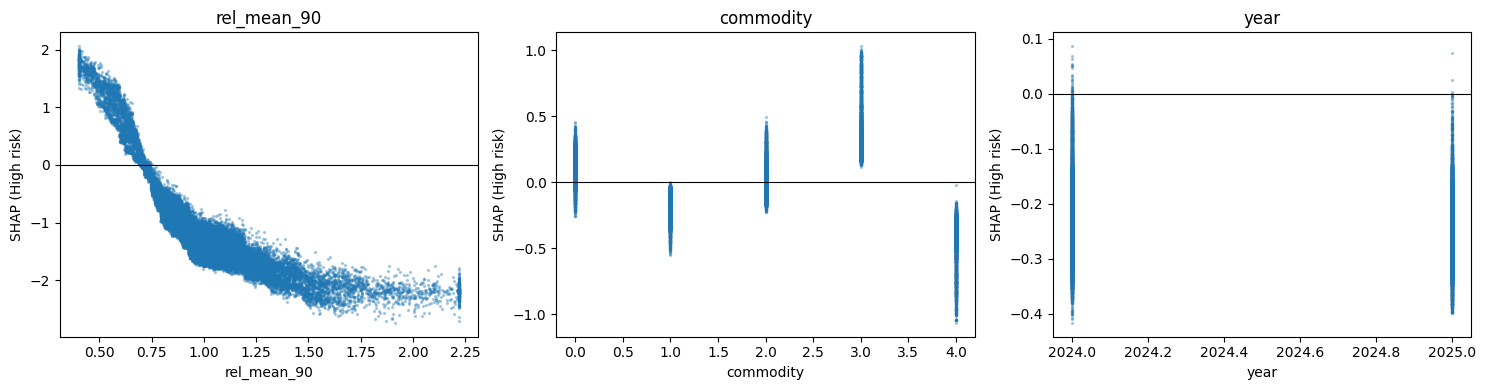


Correlation between feature value and its High-risk SHAP value (sign = direction of the effect):
rel_mean_90     -0.81
commodity       -0.24
year            -0.17
cv_30            0.84
state           -0.19
ma_30            0.75
volatility_30    0.76
season           0.86


In [ ]:
# 1. Feature importance (gain) and SHAP values
imp = pd.Series(model.feature_importances_, index=FEATS).sort_values(ascending=False)
print("XGBoost feature importance (share of total gain):\n" + imp.round(4).to_string())

# SHAP values straight from XGBoost (exact TreeSHAP). Shape: rows x classes x (features + 1 bias term)
rng = np.random.default_rng(SEED)
idx = np.sort(rng.choice(len(X), size=min(SHAP_ROWS, len(X)), replace=False))
Xs = X.iloc[idx]
contrib = model.get_booster().predict(xgb.DMatrix(Xs.to_numpy(), feature_names=FEATS), pred_contribs=True)
contrib = np.asarray(contrib).reshape(len(Xs), len(CLASS_NAMES), len(FEATS) + 1)
shap_high = pd.DataFrame(contrib[:, 2, :-1], columns=FEATS, index=Xs.index)        # contributions to the High-risk score

mean_abs = pd.DataFrame({c: np.abs(contrib[:, i, :-1]).mean(axis=0) for i, c in enumerate(CLASS_NAMES)}, index=FEATS)
mean_abs = mean_abs.sort_values("High", ascending=False)
mean_abs.to_csv(os.path.join(OUT_DIR, "shap_mean_abs.csv"))
print("\nMean |SHAP| per class (how strongly each feature moves the prediction):\n" + mean_abs.round(4).to_string())

new_share = mean_abs.loc[EXTRA, "High"].sum() / mean_abs["High"].sum()
print(f"\nShare of the High-risk SHAP total that comes from the 7 added relative features: {100 * new_share:.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
imp.head(15)[::-1].plot.barh(ax=axes[0]); axes[0].set_title("XGBoost feature importance (gain)"); axes[0].set_xlabel("share of total gain")
mean_abs["High"].head(15)[::-1].plot.barh(ax=axes[1]); axes[1].set_title("Mean |SHAP| for the High-risk class"); axes[1].set_xlabel("mean |SHAP|")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "09_importance_shap.png"), dpi=150); plt.show()

# Direction of the effect for the three strongest features: feature value vs its SHAP contribution to High risk
top3 = mean_abs.index[:3].tolist()
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, f in zip(axes, top3):
    lo, hi = Xs[f].quantile([0.01, 0.99])
    ax.scatter(Xs[f].clip(lo, hi), shap_high[f], s=2, alpha=0.3)
    ax.axhline(0, color="k", lw=0.8); ax.set_xlabel(f); ax.set_ylabel("SHAP (High risk)"); ax.set_title(f)
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "09_shap_dependence.png"), dpi=150); plt.show()
print("\nCorrelation between feature value and its High-risk SHAP value (sign = direction of the effect):")
print(pd.Series({f: np.corrcoef(Xs[f], shap_high[f])[0, 1] for f in mean_abs.index[:8]}).round(2).to_string())

In [ ]:
# 2. Error analysis: High-risk days that the model called Low (the most costly mistake for a farmer)
p_xgb, p_base, y = pred["pred_XGBoost"].to_numpy(), pred["pred_Risk persistence"].to_numpy(), pred["y_true"].to_numpy()
high = y == 2
missed, caught = high & (p_xgb == 0), high & (p_xgb == 2)
print(f"True High-risk rows: {high.sum():,} | caught as High: {caught.sum():,} | called Medium: {(high & (p_xgb == 1)).sum():,} | called Low (missed): {missed.sum():,}")

both = pd.crosstab(pd.Series(np.where(p_xgb[high] == 2, "XGBoost: High", "XGBoost: not High"), name=""),
                   pd.Series(np.where(p_base[high] == 2, "Persistence: High", "Persistence: not High"), name=""))
print("\nTrue High-risk rows - who caught them:\n" + both.to_string())

com = pd.DataFrame({"high_rows": pred[high].groupby("commodity", observed=True).size(),
                    "missed_as_low": pred[missed].groupby("commodity", observed=True).size()}).fillna(0)
com["missed_%"] = (100 * com["missed_as_low"] / com["high_rows"]).round(2)
print("\nMissed High-risk rows by commodity:\n" + com.to_string())

cols = ["rel_mean_90", "rel_ma_7", "change_1", "price_momentum", "change_30", "cv_30"]
prof = pd.DataFrame({"missed (called Low)": X.loc[missed, cols].median(), "caught (called High)": X.loc[caught, cols].median(),
                     "all test rows": X[cols].median()})
print("\nMedian feature values on the prediction day:\n" + prof.round(3).to_string())
print("\nMedian realised ratio (price at t+7 / 90-day mean):",
      {"missed": round(float(pred.loc[missed, "ratio"].median()), 3), "caught": round(float(pred.loc[caught, "ratio"].median()), 3)})

# How sudden were the missed crashes? price at t+7 relative to the price on the prediction day
drop = pred["ratio"] / pred["current_ratio"] - 1
print("Median 7-day price change:", {"missed": f"{100 * drop[missed].median():.0f}%", "caught": f"{100 * drop[caught].median():.0f}%"})
m = pred.loc[missed].assign(month=lambda d: d["date"].dt.to_period("M").astype(str))
print("\nMonths with the most missed High-risk rows:\n" + m.groupby(["month", "commodity"], observed=True).size().sort_values(ascending=False).head(8).to_string())

True High-risk rows: 50,573 | caught as High: 36,801 | called Medium: 12,102 | called Low (missed): 1,670

True High-risk rows - who caught them:
                   Persistence: High  Persistence: not High
                                                           
XGBoost: High                  30070                   6731
XGBoost: not High                 45                  13727

Missed High-risk rows by commodity:
              high_rows  missed_as_low  missed_%
commodity                                       
Brinjal            8688            633      7.29
Green Chilli       7375            375      5.08
Onion             14802            187      1.26
Potato             9816            173      1.76
Tomato             9892            302      3.05

Median feature values on the prediction day:
                missed (called Low)  caught (called High)  all test rows
rel_mean_90                   1.043                 0.542          0.994
rel_ma_7                      1.000       